In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

folder = "/content/drive/MyDrive/Cleaned data/"

movies = pd.read_csv(folder + " movies.csv")
genres = pd.read_csv(folder + " genres.csv")
movie_genres = pd.read_csv(folder + " movie_genres.csv")
cast = pd.read_csv(folder + " cast.csv")
crew = pd.read_csv(folder + " crew.csv")
movie_keywords = pd.read_csv(folder + " movie_keywords.csv")

movies["release_date"] = pd.to_datetime(movies["release_date"])

movies["release_year"] = movies["release_date"].dt.year

print("All six files loaded successfully.")
print("Movies:", movies.shape)
print("Genres:", genres.shape)
print("Movie genres:", movie_genres.shape)
print("Cast:", cast.shape)
print("Crew:", crew.shape)
print("Movie keywords:", movie_keywords.shape)

All six files loaded successfully.
Movies: (2503, 13)
Genres: (19, 2)
Movie genres: (6878, 2)
Cast: (24902, 6)
Crew: (7289, 6)
Movie keywords: (41681, 3)


**Chart 1 — Distribution of movie ratings**

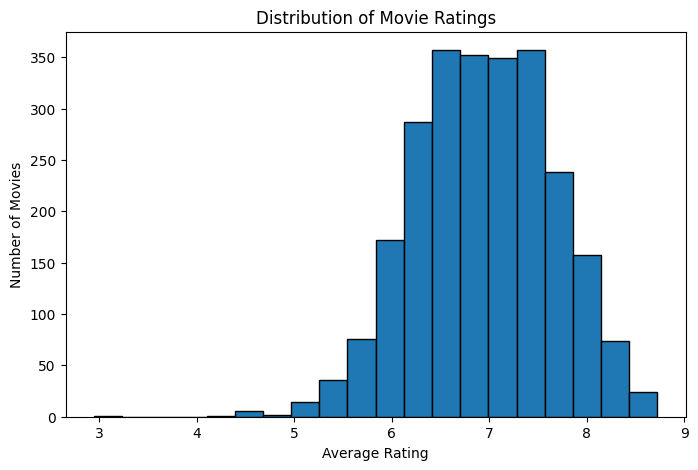

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(movies["vote_average"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.show()

# Insight: Look for the rating range with the tallest bars.

**Chart 2 — Top 10 highest-revenue movies**

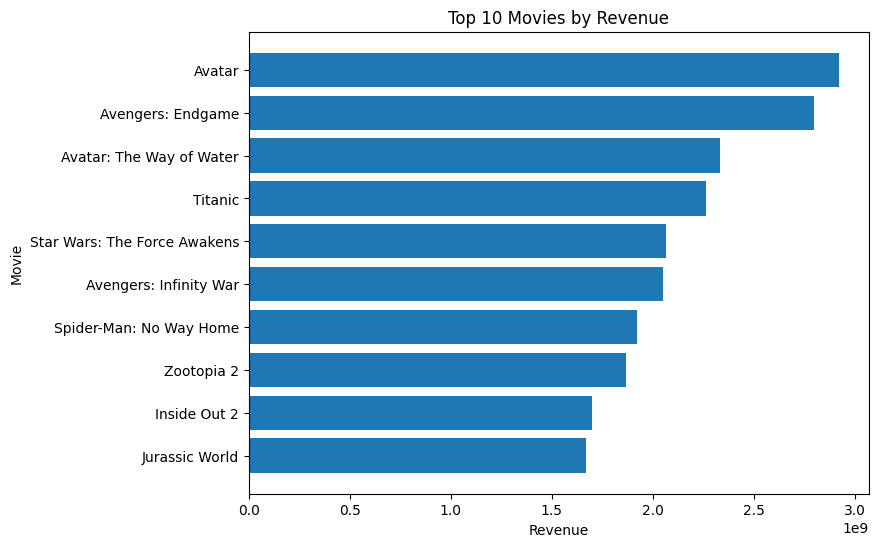

In [ ]:
top_revenue = movies[movies["revenue"] > 0]
top_revenue = top_revenue.sort_values("revenue", ascending=False).head(10)

plt.figure(figsize=(8, 6))
plt.barh(top_revenue["title"], top_revenue["revenue"])
plt.title("Top 10 Movies by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Movie")
plt.gca().invert_yaxis()
plt.show()

#Insight: The first movie has the highest revenue among these ten.


**Chart 3 — Number of movies in each genre**

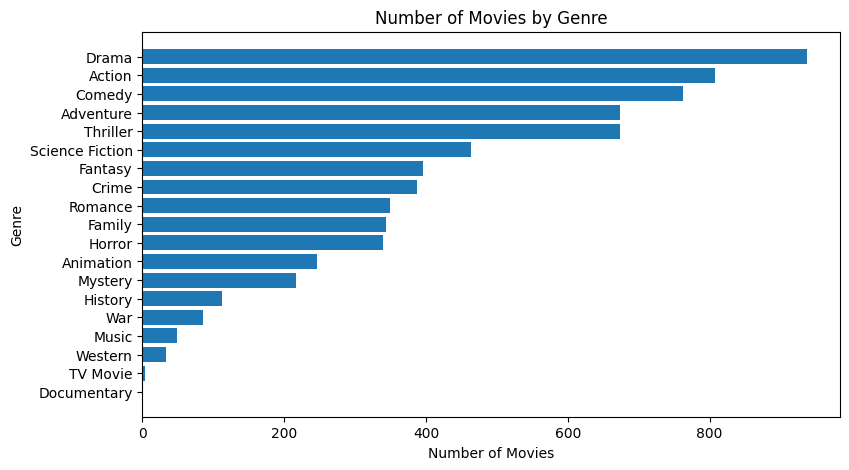

In [ ]:
genre_data = pd.merge(movie_genres, genres, on="genre_id")

genre_count = genre_data.groupby("genre_name")["movie_id"].nunique()
genre_count = genre_count.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(genre_count.index, genre_count.values)
plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.gca().invert_yaxis()
plt.show()

# Insight: The first genre has the most movies.

**Chart 4 — Average rating by genre**

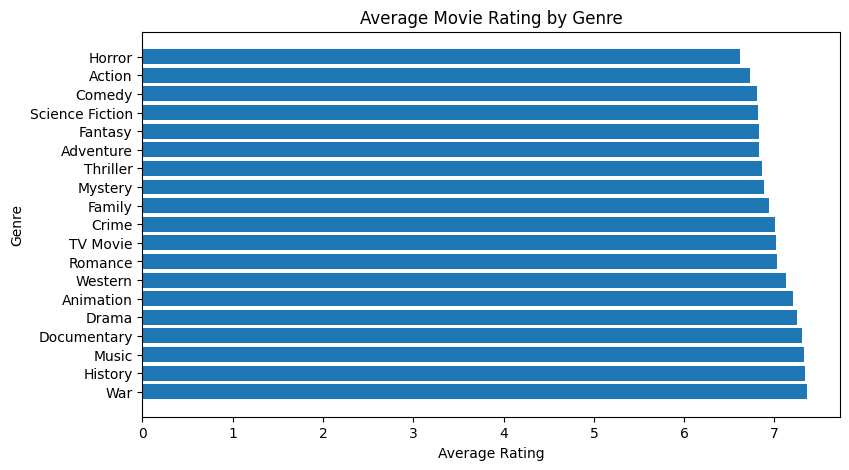

In [ ]:
genre_data = pd.merge(movie_genres, genres, on="genre_id")
genre_data = pd.merge(
    genre_data,
    movies[["movie_id", "vote_average"]],
    on="movie_id"
)

average_rating = genre_data.groupby("genre_name")["vote_average"].mean()
average_rating = average_rating.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(average_rating.index, average_rating.values)
plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.show()

# Insight: The first genre has the highest average rating.

**Chart 5 — Number of genres assigned to each movie**

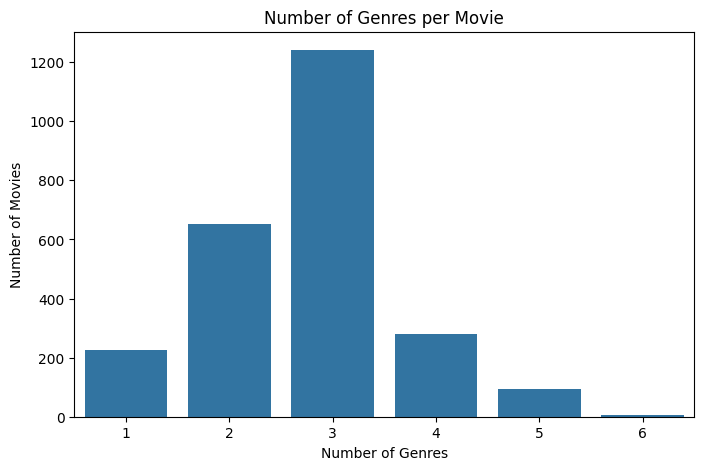

In [ ]:
genre_count_per_movie = movie_genres.groupby("movie_id")["genre_id"].nunique()

plt.figure(figsize=(8, 5))
sns.countplot(x=genre_count_per_movie)
plt.title("Number of Genres per Movie")
plt.xlabel("Number of Genres")
plt.ylabel("Number of Movies")
plt.show()

# Insight: The most frequent bar shows the usual number of genres per movie.

**Chart 6 — Number of movies by original language**

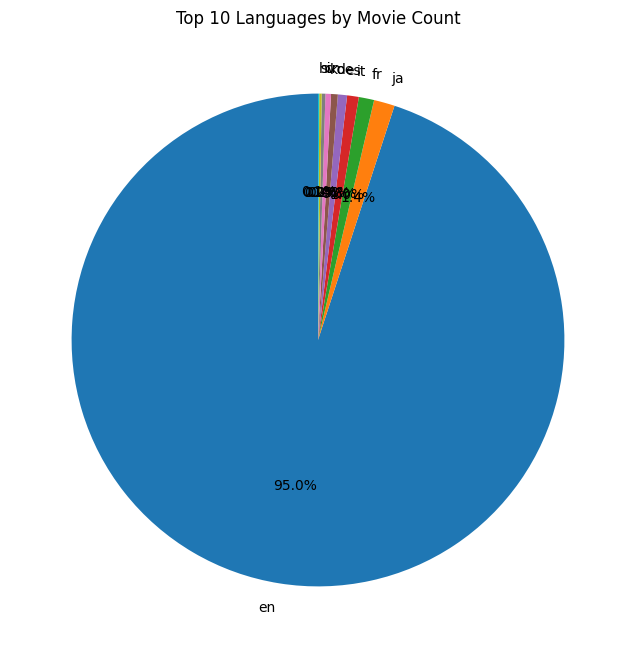

Most common language: en
Number of movies: 2363


In [ ]:
language_count = movies["original_language"].value_counts().head(10)

plt.figure(figsize=(8, 8))
plt.pie(
    language_count.values,
    labels=language_count.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Top 10 Languages by Movie Count")
plt.show()

# Insight: The largest slice represents the most common language.
print("Most common language:", language_count.index[0])
print("Number of movies:", language_count.iloc[0])

**Chart 7 — Top 10 actors by movie appearances**

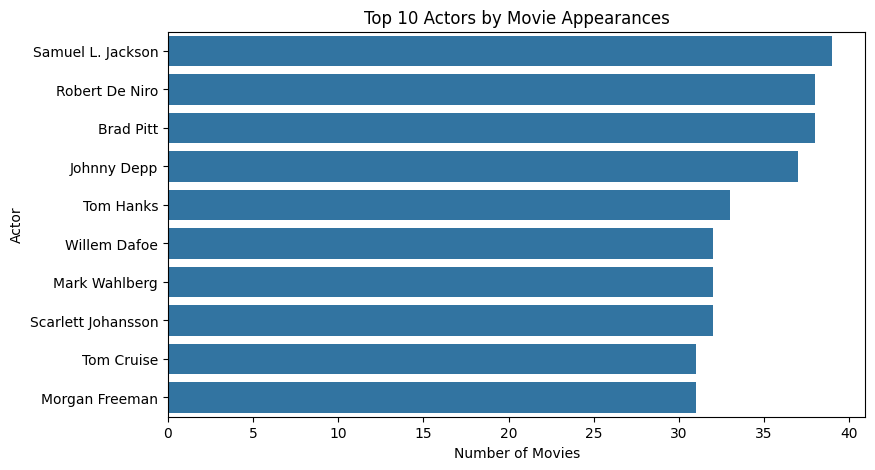

Insight guide: The longest bar represents the actor appearing in the most movies in this dataset.


In [ ]:
actor_count = cast.groupby("actor_name")["movie_id"].nunique().reset_index(name="movie_count")
top_actors = actor_count.sort_values("movie_count", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=top_actors, x="movie_count", y="actor_name")
plt.title("Top 10 Actors by Movie Appearances")
plt.xlabel("Number of Movies")
plt.ylabel("Actor")
plt.show()
print("Insight guide: The longest bar represents the actor appearing in the most movies in this dataset.")

**Chart 8 — Movies released per year**
---



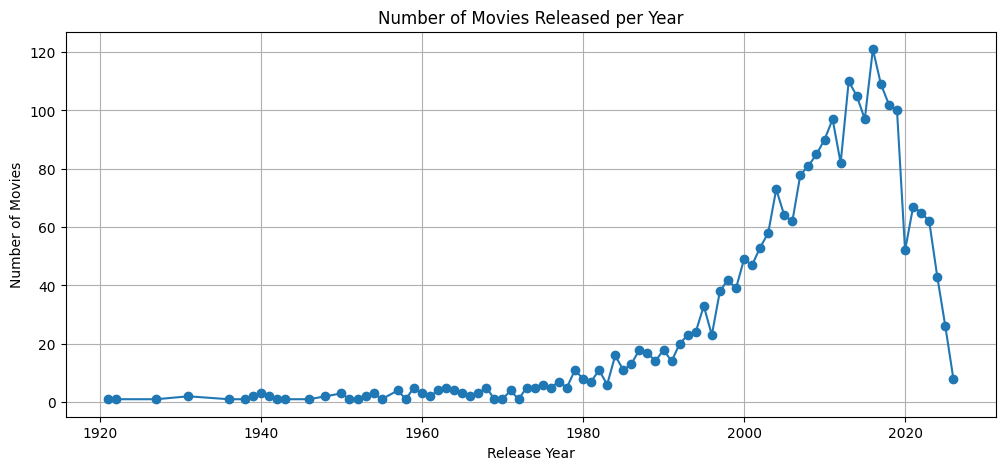

Year with most movies: 2016
Number of movies: 121


In [ ]:
movies_per_year = movies.groupby("release_year")["movie_id"].nunique()
movies_per_year = movies_per_year.dropna().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(movies_per_year.index, movies_per_year.values, marker="o")
plt.title("Number of Movies Released per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(True)
plt.show()

# Insight: The peak shows the year with the most movies in this dataset.
print("Year with most movies:", int(movies_per_year.idxmax()))
print("Number of movies:", int(movies_per_year.max()))

**Chart 9 — Top 10 directors by movie count**

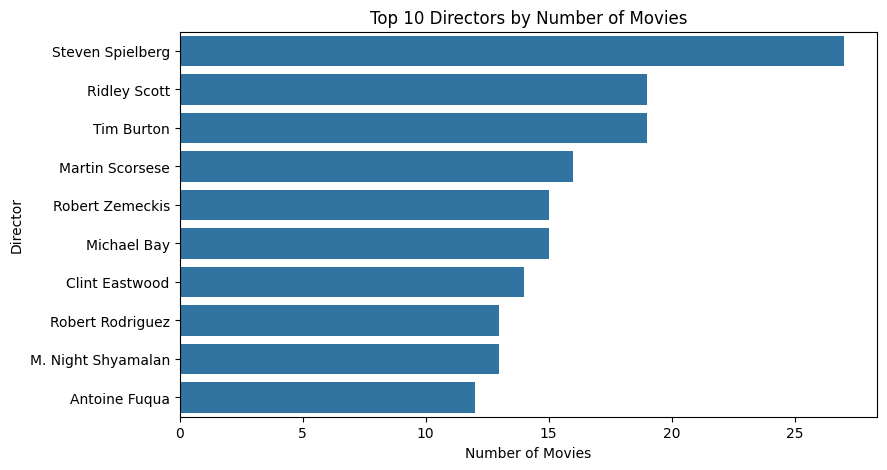

Insight guide: Identify the directors with the most movie credits.


In [ ]:
directors = crew[crew["job"].str.lower().str.strip() == "director"]
director_count = directors.groupby("person_name")["movie_id"].nunique().reset_index(name="movie_count")
top_directors = director_count.sort_values("movie_count", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=top_directors, x="movie_count", y="person_name")
plt.title("Top 10 Directors by Number of Movies")
plt.xlabel("Number of Movies")
plt.ylabel("Director")
plt.show()
print("Insight guide: Identify the directors with the most movie credits.")

**Chart 10 — Top 10 crew jobs**

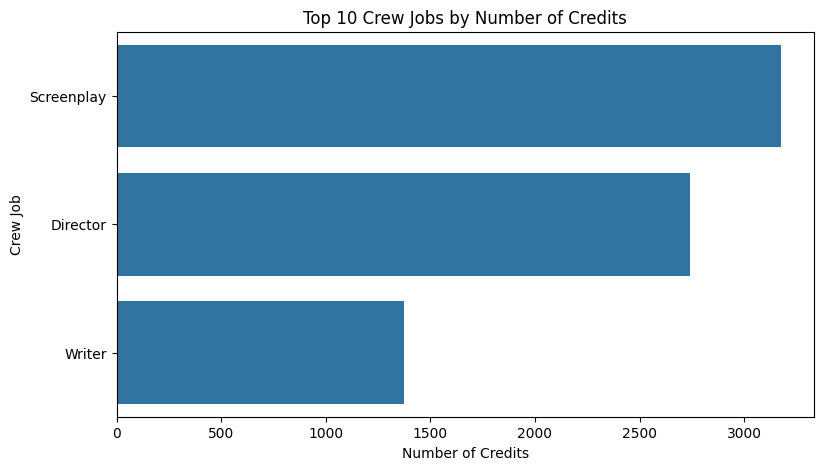

Insight guide: Identify which crew roles occur most often. These are credits, not unique people.


In [ ]:
job_count = crew["job"].value_counts().head(10).reset_index()
job_count.columns = ["job", "credit_count"]

plt.figure(figsize=(9, 5))
sns.barplot(data=job_count, x="credit_count", y="job")
plt.title("Top 10 Crew Jobs by Number of Credits")
plt.xlabel("Number of Credits")
plt.ylabel("Crew Job")
plt.show()
print("Insight guide: Identify which crew roles occur most often. These are credits, not unique people.")

**Chart 11 — Top 10 most common keywords**

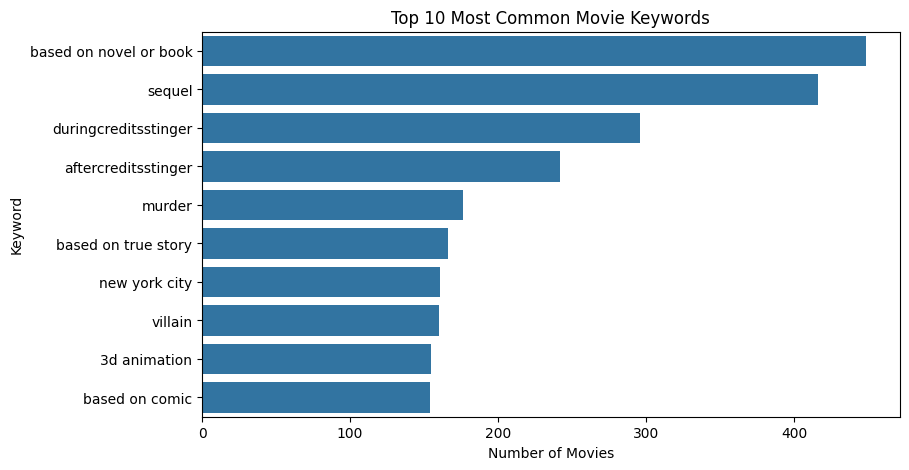

Insight guide: The longest bar represents the keyword used by the most movies.


In [ ]:
keyword_count = movie_keywords.groupby("keyword_name")["movie_id"].nunique().reset_index(name="movie_count")
top_keywords = keyword_count.sort_values("movie_count", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=top_keywords, x="movie_count", y="keyword_name")
plt.title("Top 10 Most Common Movie Keywords")
plt.xlabel("Number of Movies")
plt.ylabel("Keyword")
plt.show()
print("Insight guide: The longest bar represents the keyword used by the most movies.")

**Chart 12 — Movie budget distribution**

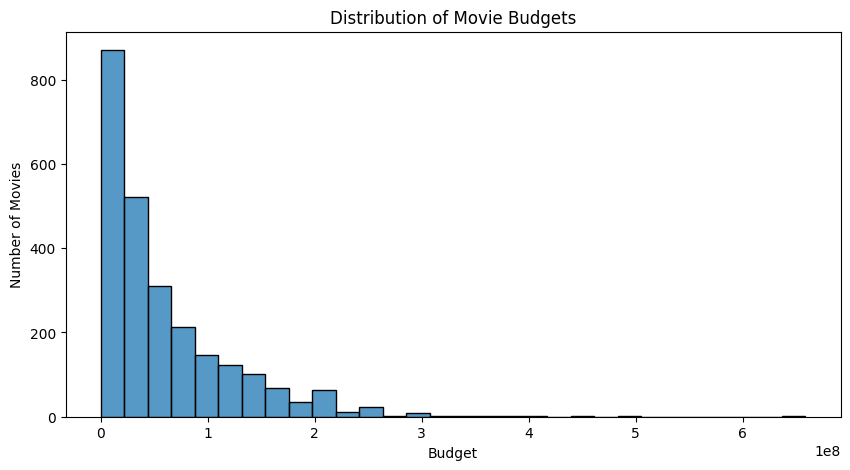

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(data=movies, x="budget", bins=30)
plt.title("Distribution of Movie Budgets")
plt.xlabel("Budget")
plt.ylabel("Number of Movies")
plt.show()

#Insight:
#Describe where most movie budgets are concentrated. Check whether a few movies have much larger budgets than most others.

**Chart -13 Popularity compared with vote count**

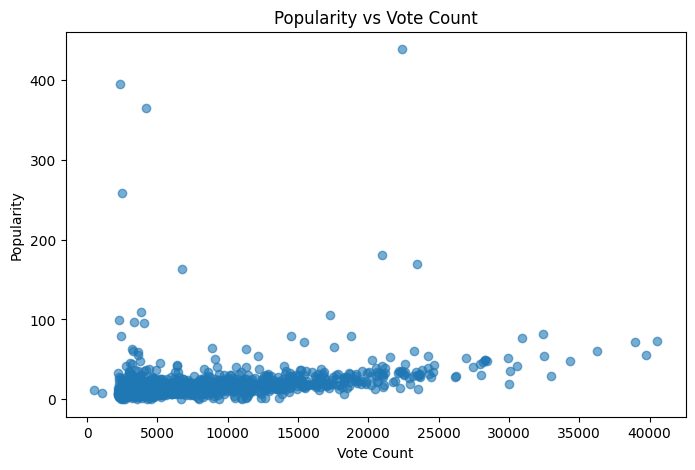

Correlation between vote count and popularity: 0.36


In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(movies["vote_count"], movies["popularity"], alpha=0.6)
plt.title("Popularity vs Vote Count")
plt.xlabel("Vote Count")
plt.ylabel("Popularity")
plt.show()

# Insight: Look for an upward, downward or unclear pattern.
correlation = movies["vote_count"].corr(movies["popularity"])
print("Correlation between vote count and popularity:", round(correlation, 2))